# Deep Learning a Stochastic Volatility Surface

Author: Sebastien Gurrieri, sebgur@gmail.com

The purpose of this notebook is to provide a simple demo of the training of DNNs to fit implied volatility surfaces within [SDevPy](https://pypi.org/project/sdevpy/). SDevPy simplifies the process of generating datasets, training models and testing them, currently applied to the calibration of interest rate implied volatility surfaces.

The principles at play here have been introduced and illustrated in a number of references. [[Hernandez 2016]](https://www.risk.net/media/download/952386/download) train a network to learn the model parameters as functions of the market prices for the Hull-White model ("inverse map"). [[Horvath et al. 2019]](https://arxiv.org/abs/1901.09647) prefer to learn the prices as functions of the model parameters ("direct map"), and apply this strategy to a number of stochastic volatility surfaces, including the rough Bergomi model. [McGhee 2018](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=3288882) uses a similar approach to learn the SABR model. [Kienitz et al. 2021](https://www.youtube.com/watch?v=48QpXv1VTl8) have extended these ideas to other stochastic volatility surfaces such as Free-Boundary SABR, ZABR and Heston.

The overarching idea behind these references is that the neural network could be used as a replacement for a traditional valuation method to price vanilla options (direct map) or possibly to infer the model parameters from option prices (inverse map). Traditional methods such as analytical expressions may not be available for certain complex models. For these models, only PDE or Monte-Carlo simulations would allow us to calculate prices for the purpose of model calibration, but optimization on PDE or MC is exceedingly costly. The neural network can then be used to off-load the calculation time to the training phase, while the on-line calibration can be performed on the trained network very quickly.

Our purpose in [SDevPy](https://pypi.org/project/sdevpy/) is to create a python framework to easily develop those ideas and share datasets as well as trained networks. Here we start with the direct map, in a very similar fashion to the work by [Kienitz et al. 2021](https://www.youtube.com/watch?v=48QpXv1VTl8) and [McGhee 2018](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=3288882). The library has a number of built-in methods to generate sample datasets and train the networks for the chosen models, which include SABR (Hagan), No-Arbitrage SABR, Free-Boundary SABR, ZABR and Heston. It can also easily download sample datasets and use pre-trained models from our [github repository](https://github.com/sebgur/SDev.Python) and [Kaggle for larger datasets](https://www.kaggle.com/sebastiengurrieri/datasets).

Generation of samples has been covered in a [previous notebook](https://colab.research.google.com/drive/1-0vRa31xcMwe8iE_U7cZATiTis17oFxL?usp=sharing). In the work here, the user may choose to:
* train a network from scratch (and test it on provided samples) or
* use a pretrained network and test it on provided samples.

This is the preliminary step towards other goals we have in mind. Namely, we think that it would be valuable to develop the inverse map for these models but also bring this work to more "complex" models such as stochastic local vol multi-factor Cheyette, and we hope that the present framework can pave the way in this direction. The saved models have been trained with various amounts of efforts and on various amounts of data, ranging from 500k to 2 million samples. As a proof of concept we spent more time on the Hagan SABR model for which it was obviously easier to generate millions of samples, but since the shapes to learn are similar in other models, we think that, provided the sample datasets are clean, similar accuracies should be reachable on the other models. Obtaining clean datasets is therefore key. We use Monte-Carlo simulation for ease of implementation, but this leads to very slow generation and noisy data. PDEs would surely offer cleaner data for faster runtime. See [Kienitz et al. 2021](https://www.youtube.com/watch?v=48QpXv1VTl8) for materials on SABR-like PDEs.

In [2]:
# Import relevant modules and set project folder
from pathlib import Path
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sdevpy import logger
from sdevpy.utilities.timer import Stopwatch
from sdevpy.volatility.mlsurfacegen import stovolfactory
from sdevpy.machinelearning import datasets
from sdevpy.volatility.impliedvol.optionsurface import plot_transform_surface
from sdevpy.maths.metrics import bps_rmse
from sdevpy.machinelearning.pytorch.topology import MlpTopology
from sdevpy.machinelearning.pytorch.learningmodel import TorchMultiLayerPerceptron, load_model, set_seed
from sdevpy.machinelearning.pytorch.losses import bps_rmse_loss
logger.configure()


# Specific project location
project_path = Path.home() / "temp" / "sdevpy" / "stovol" / "pricing"

# Check paths
project_path.mkdir(parents=True, exist_ok=True)
print(f"Project path: {project_path}")

Project path: /Users/sebgur/temp/sdevpy/stovol/pricing


## 1) Set runtime configuration


In [12]:
### Global ####
model_type = "SABR"  # SABR, McSABR, FbSABR, McZABR, McHeston
n_samples = 500_000  # Number of samples to generate into (or read from) sample files

#### Dataset generation ####
generate_dataset = False  # If False, read pre-generated files
shift = 0.03  # For negative rates
# The 4 parameters below are only relevant for models based on MC
n_expiries, n_strikes = 10, 5
n_mc, points_per_year = 10_000, 25
gen_seed = 42  # [2468, 8642, 2112, 4444, 88, 6666, 1122, 12]

#### Training ####
model_start_version = "h3-n16-0.0"  # "h3-n16-0.0" # Pre-train if None
train = True  # If False, we only load and test a pre-trained model
train_percent = 0.90  # Proportion of dataset used for training (rest used for test)
epochs = 1000
batch_size = 1000
init_lr = 1.0e-2 # Initial learning rate
lr_scheduler_type = 'floored_exponentialdecay'  # floored_exponentialdecay, cyclical_exponentialdecay, step, linear

#### Setup ####
pretrained_id = f"{model_type}-{model_start_version}" # Used if model_start_version is not None
use_pretrained = (model_start_version is not None)
if use_pretrained is False and train is False:
    raise RuntimeError("When not using pre-trained models, a new model must be trained")

# Paths
dataset_path = project_path / "datasets" / model_type
dataset_path.mkdir(parents=True, exist_ok=True)
print(f"Data folder: {dataset_path}")

model_path = project_path / "models" / model_type
model_path.mkdir(parents=True, exist_ok=True)
print(f"Model folder: {model_path}")

print(f"Model type: {model_type}")
if use_pretrained:
    print(f"Starting from: pretrained {pretrained_id}")
else:
    print("Starting from: new")

print(f"Number of samples in dataset: {n_samples:,}")
print(f"Training: {'on' if train else 'off'}")

# Select the model
generator = stovolfactory.set_generator(model_type)

Data folder: /Users/sebgur/temp/sdevpy/stovol/pricing/datasets/SABR
Model folder: /Users/sebgur/temp/sdevpy/stovol/pricing/models/SABR
Model type: SABR
Starting from: pretrained SABR-h3-n16-0.0
Number of samples in dataset: 500,000
Training: on


## 2) Prepare the datasets

Datasets need to be read even if we do not train, as we are using to evaluate the performance of the model. Here the dataset can be generated from scratch or read in files where previously generated data was saved. The data is loaded from the files, and we prepare training and test sets.


In [13]:
# Generate data if requested
if generate_dataset:
    # Specify parameter ranges to generate randomly distributed samples
    sabr_range = {'Ttm': [1.0 / 12.0, 35.0], 'K': [0.01, 0.99], 'F': [-0.009, 0.041], 'LnVol': [0.05, 0.5],
                  'Beta': [0.1, 0.9], 'Nu': [0.1, 1.0], 'Rho': [-0.6, 0.6]}
    fbsabr_range = {'Ttm': [1.0 / 12.0, 10.0], 'K': [0.01, 0.99], 'F': [-0.01, 0.05], 'LnVol': [0.05, 0.5],
                    'Beta': [0.25, 0.75], 'Nu': [0.1, 1.0], 'Rho': [-0.6, 0.6]}
    zabr_range = {'Ttm': [1.0 / 12.0, 35.0], 'K': [0.01, 0.99], 'F': [-0.009, 0.041], 'LnVol': [0.05, 0.5],
                  'Beta': [0.1, 0.9], 'Nu': [0.10, 1.0], 'Rho': [-0.6, 0.6],
                  'Gamma': [0.1, 0.9]}
    heston_range = {'Ttm': [1.0 / 12.0, 35.0], 'K': [0.01, 0.99], 'F': [-0.009, 0.041], 'LnVol': [0.05, 0.25],
                    'Kappa': [0.25, 4.00], 'Theta': [0.05**2, 0.25**2], 'Xi': [0.10, 0.50],
                    'Rho': [-0.40, 0.40]}

    # Map models types to ranges
    model_range_map = {'SABR': sabr_range, 'McSABR': sabr_range, 'FbSABR': fbsabr_range, 'McZABR': zabr_range,
                       'McHeston': heston_range}

    # Create data generator object
    sample_gen = stovolfactory.set_generator(model_type, shift, n_expiries, n_strikes, n_mc, points_per_year, gen_seed)

    # Generate samples (prices)
    print(f"Generating {n_samples:,} price samples")
    data_df = sample_gen.generate_samples(n_samples, model_range_map[model_type])

    # Convert to normal vols and cleanse
    print("Convert to normal vol and cleanse data")
    data_df = sample_gen.to_nvol(data_df, cleanse=True)
    num_clean = len(data_df.index)
    print(f"Dataset size after cleansing: {num_clean:,}")

    # Output to file
    now = dt.datetime.now()
    dt_string = now.strftime("%Y%m%d-%H_%M_%S")
    data_file = dataset_path / f"{model_type}_data_{dt_string}.tsv"
    print(f"Output to file {data_file}")
    sample_gen.to_file(data_df, data_file)

In [14]:
# Retrieve data from dataset folder: will combine several files if needed to reach sample size
print(f"Requested {n_samples:,} samples")
train_data_file = project_path / "datasets" / "train.tsv"
datasets.retrieve_data(dataset_path, n_samples, shuffle=True, export_file=train_data_file)
print(f"Exporting dataset to file: {train_data_file}")

# Read data from the prepared data file
print(f"Reading dataset from: {train_data_file}")
x_set, y_set, data_df = generator.retrieve_datasets(train_data_file, shuffle=True)
input_dim = x_set.shape[1]
output_dim = y_set.shape[1]
print("Input dimension: " + str(input_dim))
print("Output dimension: " + str(output_dim))
print("Dataset extract")
print(data_df.head())
# Split into training and test sets
TRS = train_percent * 100
print(f"Splitting between training set ({TRS:.2f}%) and test set ({100 - TRS:.2f}%)")
x_train, y_train, x_test, y_test = datasets.prepare_sets(x_set, y_set, train_percent)

Requested 500,000 samples
Exporting dataset to file: /Users/sebgur/temp/sdevpy/stovol/pricing/datasets/train.tsv
Reading dataset from: /Users/sebgur/temp/sdevpy/stovol/pricing/datasets/train.tsv
Input dimension: 7
Output dimension: 1
Dataset extract
              Ttm         K         F     LnVol      Beta        Nu       Rho  \
424778  14.121538  0.009599  0.031692  0.234511  0.487495  0.309597 -0.127899   
453725   3.005523  0.033113  0.040233  0.103645  0.374192  0.583585  0.127258   
431693  26.857930 -0.027251  0.011189  0.396910  0.573752  0.824974  0.562389   
95616   19.351528 -0.010545  0.012141  0.208963  0.398771  0.518805 -0.111172   
261345  28.639841  0.276631  0.007154  0.316870  0.898228  0.934715 -0.128288   

           Price      NVol  
424778  0.012611  0.014614  
453725  0.002612  0.007877  
431693  0.002749  0.007046  
95616   0.011567  0.011959  
261345  0.306631  0.060765  
Splitting between training set (90.00%) and test set (10.00%)


## 3) Compose the learning model

If we load a pre-trained model, we read its characteristics for display. However if we chose to start training a fresh new model, we need to specify its topology. Note that we use our own wrapper (TorchMultiLayerPerceptron) above the PyTorch model. It includes scalers and various additional functionalities for loading and saving.

In [15]:
if use_pretrained:
    print(f"<><> Loading pretrained model ID: {pretrained_id} <><>")
    pretrained_path = model_path / pretrained_id
    print(f"Model path: {pretrained_path}")
    model = load_model(pretrained_path)
else:
    set_seed(42)
    print("<><> Composing new model <><>")
    activations = ['softplus', 'softplus', 'softplus'] # relu, tanh, elu, selu, gelu, softplus
    neurons, dropout = 16, 0.0
    model = TorchMultiLayerPerceptron(MlpTopology(input_dim, output_dim, activations, neurons, dropout))

# Display topology
model.topology.pretty_print()

<><> Loading pretrained model ID: SABR-h3-n16-0.0 <><>
Model path: /Users/sebgur/temp/sdevpy/stovol/pricing/models/SABR/SABR-h3-n16-0.0
Input dimension: 7
Output dimension: 1
Hidden layers: 3
Activations: ['softplus', 'softplus', 'softplus']
Neurons per layer: 16
Drop-out: 0.0


## 4) Training

If the user chose to train, training will start here by specifying the learning schedule in a custom class for which the learning rate starts at INIT_LR and decreases exponentially down to FINAL_LR. As a rule of thumb from trial and error, we find that for fresh training INIT_LR=1e-1 tends to produce good results, while for focusing accuracy of a pre-trained model, smaller learning rates around 1e-2 or 1e-3 are better. The following learning rate types are available:
* constant (no args)
* floored_exponentialdecay (n_samples, batch_size, target_epoch, final_lr)
* cyclical_exponentialdecay (n_samples, batch_size, target_epoch, final_lr)
* step (n_samples, batch_size, n_epochs_between_drops, gamma)
* linear (n_samples, batch_size, n_epochs, final_lr)
* lambda (lr_lambda, a lambda expression representing a function of the step)

The training also includes a step that periodically calculates the loss (RMSE) on the test set to watch for over-fitting.

In [16]:
lrs = {'floored_exponentialdecay': {'n_samples': n_samples, 'batch_size': batch_size, 'target_epoch': 0.9 * epochs,
                                    'final_lr': 1e-3},
       'cyclical_exponentialdecay': {'n_samples': n_samples, 'batch_size': batch_size, 'target_epoch': 0.9 * epochs,
                                    'final_lr': 1e-4},
       'warmup_cosine': {'warmup_epochs': 0.20 * epochs, 'total_epochs': epochs, 'min_lr': 1e-4},
       'step': {'n_samples': n_samples, 'batch_size': batch_size, 'n_epochs_between_drops': 20, 'gamma': 0.9},
       'linear': {'n_samples': n_samples, 'batch_size': batch_size, 'n_epochs': epochs, 'final_lr': 1e-4}
}

# Lambda expression
steps_per_epoch = n_samples / batch_size
total_steps = epochs * steps_per_epoch
def linear_decay(step):
    return max(0.1, 1.0 - 0.9 * step / total_steps)
lrs['lambda'] = {'lr_lambda': linear_decay}

epoch_sampling = 5 # Compare on test set every epoch_sampling epochs

if train:
    model.set_loss(bps_rmse_loss)
    model.set_optimizer('adam', init_lr)
    model.set_lr_scheduler(lr_scheduler_type, **lrs[lr_scheduler_type])
    model.set_sample_testing(epoch_sampling, x_test, y_test)
    model.train(x_train, y_train, epochs, batch_size, shuffle=True)

INFO | <><><><><><><><> TRAINING START <><><><><><><><>
INFO | Epochs: 1000
INFO | Batch size: 1,000
INFO | Training set size: 449,422
INFO | <><><><><><><><><><><><><><><><><><><><><><><><>
INFO | Epoch 1/1000


INFO | Loss: 789.61, LR: 0.009960
INFO | Test loss: 766.95
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 2/1000
INFO | Loss: 754.55, LR: 0.009919
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 3/1000
INFO | Loss: 756.11, LR: 0.009879
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 4/1000
INFO | Loss: 751.32, LR: 0.009839
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 5/1000
INFO | Loss: 756.25, LR: 0.009800
INFO | Test loss: 842.40
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 6/1000
INFO | Loss: 734.23, LR: 0.009760
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 7/1000
INFO | Loss: 748.48, LR: 0.009721
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 8/1000
INFO | Loss: 744.16, LR: 0.009682
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 9/1000
INFO | Loss: 744.00, LR: 0.009643
INFO | <><><><><><><><><><><><><><><><>
INFO | Epoch 10/1000
INFO | Loss: 727.50, LR: 0.009604
INFO | Test loss: 828.60
INFO | <><><><><><><><><><><><><><><><>
INFO

## 5) Tests and Diagnostics
The model, which may have simply been loaded or trained, is now evaluated on the training and test sets. We also use a specific point to display in charts the comparison between the model and the reference (on which it was trained, which may come from closed-form, PDE or MC). The chart comparison can be done on 3 possible variables (called TRANSFORM here): the prices, the Bachelier or Shifted Black-Scholes implied volatilities. Finally, if the model was trained here, we show the evolution of the training loss and learning schedule.

RMSE(nvol) on training set: 4.33
RMSE(nvol) on test set: 4.90
Choosing a sample parameter set to display chart
Calculating chart surface with reference model
Calculating chart surface with trained model
Ref-Mod RMSE(price): 1.19

Runtime(Reference surface calculation): 0.0s
Runtime(Model surface calculation): 0.0s


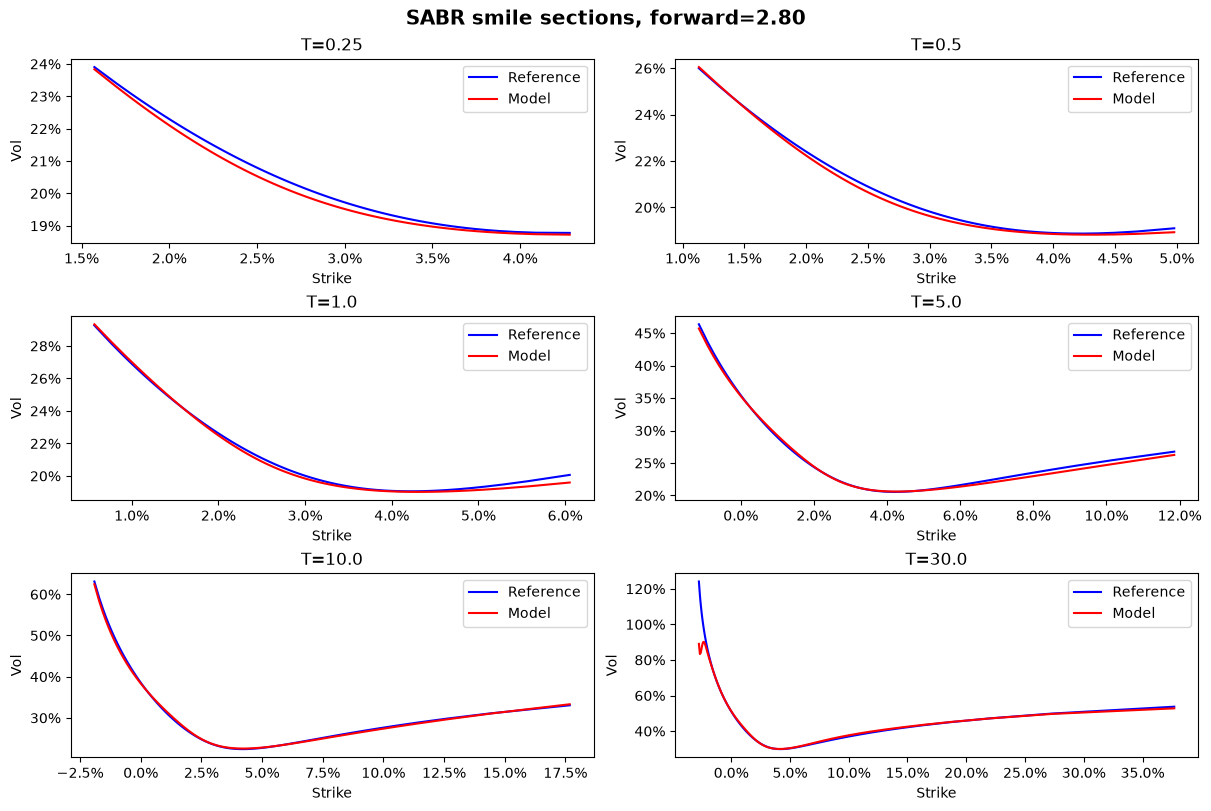

In [17]:
# Check performance
train_pred = model.predict(x_train)
train_rmse = bps_rmse(train_pred, y_train)
print(f"RMSE(nvol) on training set: {train_rmse:,.2f}")

test_pred = model.predict(x_test)
test_rmse = bps_rmse(test_pred, y_test)
print(f"RMSE(nvol) on test set: {test_rmse:,.2f}")

# Generate strike spread axis
print("Choosing a sample parameter set to display chart")
n_strikes = 100
params = {'LnVol': 0.20, 'Beta': 0.5, 'Nu': 0.55, 'Rho': -0.25, 'Gamma': 0.7, 'Kappa': 1.0,
          'Theta': 0.03, 'Xi': 0.35}
fwd = 0.028

# Any number of expiries can be calculated, but for optimum display choose no more than 6
expiries = np.asarray([0.25, 0.50, 1.0, 5.00, 10.0, 30.0]).reshape(-1, 1)
n_expiries = expiries.shape[0]
method = 'Percentiles'
percents = np.linspace(0.01, 0.99, num=n_strikes)
percents = np.asarray([percents] * n_expiries)

strikes = generator.convert_strikes(expiries, percents, fwd, params, method)
are_calls = [[False] * n_strikes] * n_expiries # All puts

print("Calculating chart surface with reference model")
timer_ref = Stopwatch("Reference surface calculation")
timer_ref.trigger()
# For comparison to reference values (MC based models, accuracy can be set in generator)
ref_prices = generator.price_surface_ref(expiries, strikes, are_calls, fwd, params)
timer_ref.stop()

print("Calculating chart surface with trained model")
timer_mod = Stopwatch("Model surface calculation")
timer_mod.trigger()
mod_prices = generator.price_surface_mod(model, expiries, strikes, are_calls, fwd, params)
timer_mod.stop()

print(f"Ref-Mod RMSE(price): {bps_rmse(ref_prices, mod_prices):.2f}")

# Display timers
print()
timer_ref.print()
timer_mod.print()

title = f"{model_type} smile sections, forward={fwd*100:.2f}" #,%\n parameters={params}"
transform = "ShiftedBlackScholes" # ShiftedBlackScholes, Bachelier, Price
plot_transform_surface(expiries, strikes, are_calls, fwd, ref_prices, mod_prices, title,
                       transform=transform)

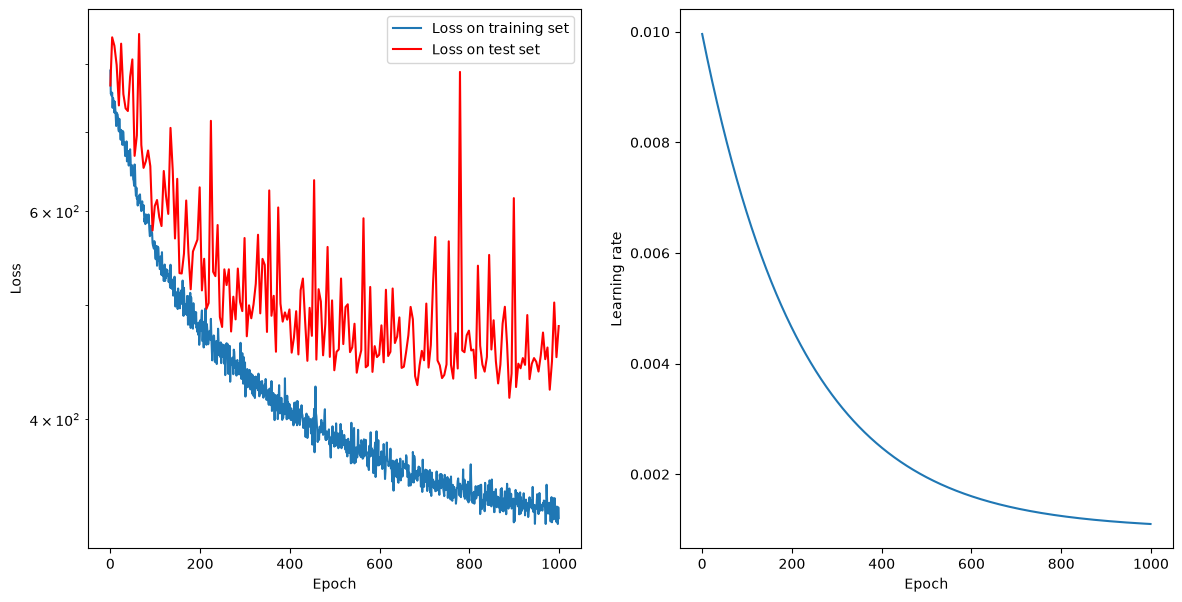

In [18]:
# Show training history
if train:
    hist_epochs = model.hist_epochs
    hist_losses = model.hist_losses
    hist_lr = model.hist_lr
    sampled_epochs = model.test_epochs
    test_losses = model.test_losses

    plt.figure(figsize=(14, 7))
    plt.subplots_adjust(hspace=0.40)

    plt.subplot(1, 2, 1)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.yscale("log")
    plt.plot(hist_epochs, hist_losses, label='Loss on training set')
    plt.plot(sampled_epochs, test_losses, color='red', label='Loss on test set')
    plt.legend(loc='upper right')
    plt.subplot(1, 2, 2)
    plt.xlabel('Epoch')
    plt.ylabel('Learning rate')
    plt.plot(hist_epochs, hist_lr)

    plt.show()

### Gradient diagnostics

The single most useful metric to watch for vanishing gradients is the ratio between the gradient norms of the last against the first layers. In the test below we display metrics on the gradients and the ratio of last/first.

What to look for:

* Healthy: gradient norms across layers stay within roughly the same order of magnitude. Some variation is normal. Ratios somewhere around 5–50x are unremarkable.

* Suspicious: the ratio spans 2+ orders of magnitude (100x+), especially if it is systematically decreasing as we move from output back toward input. That is the typical shape of the vanishing-gradient problem: gradient magnitude shrinking layer by layer as it backpropagates.

* Clear vanishing gradients: early-layer mean_abs/norm values sitting near float32's practical noise floor for gradients (roughly 1e-7 or smaller) while later layers are several orders larger. At that point those early layers are receiving essentially no learning signal.

There is no single universal numeric cutoff. It depends on loss scale, learning rate, and how deep your network is. That is why the relative comparison across layers is more diagnostic than any absolute threshold.

#### How to interpret the bars

Each bar corresponds to metrics on weights between two layers. For an MLP, the weights are found:
* between the input layer, whose dimension is the dimension of the input data and the first hidden layer, whose dimension is the chosen number of neurons (input_dim x neurons)
* between each hidden layer and the next hidden layer (neurons x neurons)
* between the last hidden layer and the output layer (neurons x output_dim).

In the case of a network with 3 hidden layers, there are therefore 4 bars. The indexes are multiples of 3 due to the nature of the MLP and PyTorch's syntax. The left-most bar corresponds to the weights between the input layer and the first hidden layer, and the next bars are in order of progression through the network, until the last bar that corresponds to the weights between the last hidden layer and the output layer.

#### Metrics
'norm': sqrt(sum(g² for g in grad)) across every element in the weight (or bias) tensor for that layer. It is a single number summarizing the overall magnitude of the gradient for that parameter.

#### Other considerations
A cheap sanity confirmation, if the ratio looks borderline: gradient magnitude only matters insofar as it drives an actual weight update (Δweight ≈ learning_rate × gradient). When unsure whether a small gradient is "vanishing" or just "this network does not need much correction here", we could compare a layer's weights before and after a few training epochs. If the earliest layer's weights are barely moving at all while later layers visibly change, that confirms the layer is functionally stuck, not just momentarily quiet.

Also worth checking: does the pattern hold across multiple batches/epochs, or was it just one snapshot? A single low reading could be an artifact of that particular batch (especially with dropout active). Implementing epoch-by-epoch tracking could show if the ratio stays bad or worsens over training. This would be a much stronger signal than a one-off measurement.

If that is confirmed, the usual suspects are:
* sigmoid/tanh/logsigmoid saturate for large |input|, producing near-zero derivatives. Switching to a ReLU-family activation (relu, elu, gelu, silu) usually resolves it outright.
* very deep stacks compound the problem. Each layer's small derivative multiplies through the chain rule, so it gets exponentially worse with depth. Fewer/wider layers can help.
* weight init scale: Xavier init (default) is specifically chosen to keep variance roughly constant across layers, so if vanishing gradients are observed despite that, the activation choice is the more likely cause.

Last/first ratio: 0.84
Test result: PASS


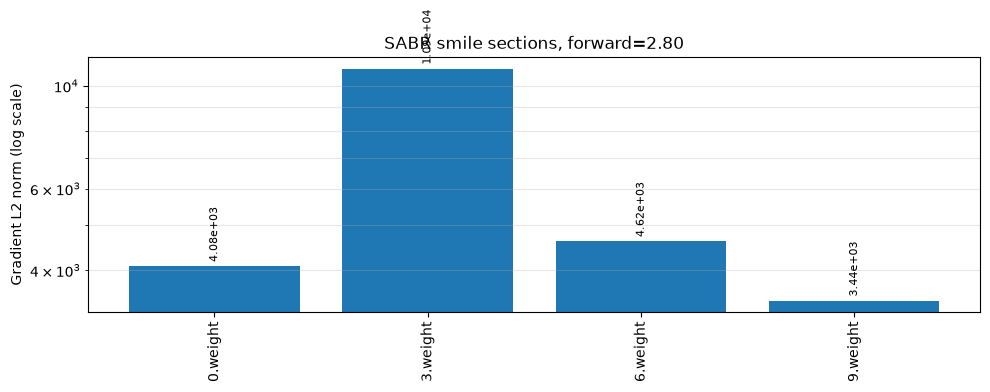

In [19]:
# Plot gradients for biases or weights
plot_for_weights = True
metric = 'norm' # mean_abs, std, norm, max_abs

# Run gradient diagnostic
stats = model.diagnose_gradients(x_set, y_set)

# Select results
names, norms = [], []
series_kw = ('weight' if plot_for_weights else 'bias')
for key, value in stats.items():
    if series_kw in key:
        names.append(key)
        norms.append(value[metric])

# Calculate ratio last / first
last_over_first = norms[-1] / norms[0]
print(f"Last/first ratio: {last_over_first:,.2f}")
print(f"Test result: {'PASS' if last_over_first < 100 else 'FAIL'}")

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(names, norms)
ax.set_yscale('log')

# Force every decade in range to get a labeled tick, not just one
ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0, numticks=15))
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs='auto', numticks=15))
ax.grid(True, which='both', axis='y', alpha=0.3)

# Print the exact value above each bar so you don't need to read the axis at all
ax.bar_label(bars, labels=[f"{n:.2e}" for n in norms], rotation=90, padding=3, fontsize=8)

plt.xticks(rotation=90)
plt.ylabel("Gradient L2 norm (log scale)")
plt.title(title)
plt.tight_layout()
plt.show()

In [20]:
# Save model
new_version = 'h3-n16-0.1'
saving_name = f"{model_type.lower()}-{new_version}"
model.save(model_path / saving_name)